In [1]:
# Supplementary figure: marginal effects of centrality on adaptation finance at
# different percentiles of disaster exposure (gravity IV and Bartik IV).
# Reads  : output/tables/Moderation_disaster_Table2_Marginal_Effects_CF{,_Bartik}.csv (module 06)
# Writes : output/figures/SuppFig_moderation_disaster_{gravityIV,BartikIV}_marginal_effects.{pdf,png}
# Ported from Figures/SuppFig_disaster_marginal_effect_by_quatile.ipynb; units are USD million.
# Error bars are 95% normal-approximation CIs (ME +/- 1.96 x SE) and stars come from the same test,
# where SE is the SD of the bootstrap replicates (output/bootstrap/mod0{6,7}_*_mediff_*.dta), i.e. the
# plain bootstrap SE as in Fig. 6 (1% trimmed in each tail until 2026-10-26; see TRIM).
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TABLES = "../output/tables"
FIGURES = "../output/figures"
os.makedirs(FIGURES, exist_ok=True)

# =========================================================
# 1. Global plot style
# =========================================================
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.8,
    'ytick.direction': 'out',
    'xtick.direction': 'out',
    'xtick.bottom': False
})


# =========================================================
# 2. Centrality measures
# =========================================================
VARS = [
    'in_degree',
    'out_degree',
    'closeness',
    'eigenvector'
]

COLS = {
    'in_degree': '(1)',
    'out_degree': '(2)',
    'closeness': '(3)',
    'eigenvector': '(4)'
}

TITLES = {
    'in_degree': 'Import Prominence (In-Degree)',
    'out_degree': 'Export Prominence (Out-Degree)',
    'closeness': 'Trade Accessibility (Closeness)',
    'eigenvector': 'Systemic Importance (Eigenvector)'
}


# =========================================================
# 3. Cleaning helpers
# =========================================================
def clean(x):
    """
    Clean strings exported by Stata esttab, e.g.
    ="ME at P50" -> ME at P50
    ="0.118***"  -> 0.118***
    """
    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    # ="text"
    match = re.fullmatch(r'=\s*"([\s\S]*)"', x)
    if match:
        return match.group(1).strip()

    # ='text'
    match = re.fullmatch(r"=\s*'([\s\S]*)'", x)
    if match:
        return match.group(1).strip()

    # Leftover leading equals sign
    if x.startswith("="):
        x = x[1:].strip()

    # Paired quotes
    if len(x) >= 2 and (
        (x[0] == '"' and x[-1] == '"') or
        (x[0] == "'" and x[-1] == "'")
    ):
        x = x[1:-1].strip()

    return x


def num(x):
    """Extract the number, dropping parentheses and significance stars."""
    x = clean(x)

    if pd.isna(x) or x == "":
        return np.nan

    try:
        return float(
            str(x)
            .replace("*", "")
            .replace("(", "")
            .replace(")", "")
            .strip()
        )
    except ValueError:
        return np.nan


def stars(x):
    """Extract significance stars."""
    x = str(clean(x))

    if "***" in x:
        return "***"
    if "**" in x:
        return "**"
    if "*" in x:
        return "*"

    return ""


# =========================================================
# 4. Read the regression table
# =========================================================
def load_table(csv_file):
    """
    The first row is the table title, so it is skipped;
    the second row holds the column names.
    """
    df = pd.read_csv(
        csv_file,
        sep=",",
        engine="python",
        dtype=str,
        keep_default_na=False,
        skiprows=1
    )

    # Clean column names and cells
    df.columns = [clean(c) for c in df.columns]
    df = df.map(clean)

    # Keep the first five columns
    df = df.iloc[:, :5].copy()

    # Standard column names
    df.columns = [
        "Variable",
        "(1)",
        "(2)",
        "(3)",
        "(4)"
    ]

    df["Variable"] = (
        df["Variable"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    return df


# =========================================================
# 5. Marginal effects at the chosen percentiles
# =========================================================
def get_vals(df, col, percentiles):
    """
    For one centrality measure, return at each moderator percentile:
    - marginal effect
    - standard error
    - significance stars
    """
    marginal_effects = []
    standard_errors = []
    significance = []

    for percentile in percentiles:
        label = f"ME at {percentile}"

        idx = df.index[df["Variable"].eq(label)]

        if len(idx) == 0:
            available = df.loc[
                df["Variable"].str.startswith("ME at", na=False),
                "Variable"
            ].tolist()

            raise ValueError(
                f"Row not found: {label}\n"
                f"Marginal-effect rows in the table: {available}"
            )

        i = idx[0]

        # This row holds the marginal effect, the next row its standard error
        me = num(df.loc[i, col])
        se = num(df.loc[i + 1, col])
        star = stars(df.loc[i, col])

        if np.isnan(me):
            raise ValueError(
                f"Marginal effect for {label} in column {col} is not numeric: "
                f"{df.loc[i, col]}"
            )

        if np.isnan(se):
            raise ValueError(
                f"Standard error for {label} in column {col} is not numeric: "
                f"{df.loc[i + 1, col]}"
            )

        marginal_effects.append(me)
        standard_errors.append(se)
        significance.append(star)

    return (
        np.asarray(marginal_effects, dtype=float),
        np.asarray(standard_errors, dtype=float),
        significance
    )


BOOTDRAWS = "../output/bootstrap"
TRIM = 0.0  # share of replicates dropped in each tail; 0 = plain bootstrap SE, as in Fig. 6


def trimmed_se(x, trim=TRIM):
    """Bootstrap SD after dropping the top and bottom `trim` share of replicates."""
    x = x.dropna()
    lo, hi = x.quantile([trim, 1 - trim])
    return x[x.between(lo, hi)].std()


def get_se_vals(df, draws, col, percentiles):
    """Point estimates from the esttab table, 95% normal CI (ME +/- 1.96 x trimmed
    bootstrap SE) and stars from the same normal test."""
    y = []
    for p in percentiles:
        i = df.index[df["Variable"].eq(f"ME at {p}")][0]
        y.append(num(df.loc[i, col]))
    y = np.array(y)
    se = np.array([trimmed_se(draws[f"me_{p.lower()}"]) for p in percentiles])
    z = np.abs(y / se)
    st = ["***" if v > 2.576 else "**" if v > 1.960 else "*" if v > 1.645 else "" for v in z]
    return y, y - 1.96 * se, y + 1.96 * se, st


# =========================================================
# 6. Plot function
# =========================================================
def plot_moderation_effects(
    csv_file,
    percentiles,
    moderator_label,
    output_prefix,
    panel_label=None,
    figure_title=None,
    show_stars=True
):
    """
    2x2 marginal-effect figure for one IV specification.

    Parameters
    ----------
    csv_file:
        Regression result CSV.

    percentiles:
        Percentiles to show, e.g. ['P50', 'P75', 'P90', 'P95'].

    moderator_label:
        x-axis label (moderator name).

    output_prefix:
        Output file name without extension.

    panel_label:
        Panel letter, e.g. 'a', 'b', 'c'.

    figure_title:
        Overall title (usually omitted in the paper).

    show_stars:
        Whether to append significance stars to the value labels.
    """

    df = load_table(csv_file)
    # Bootstrap replicates: mod06 = disaster, mod07 = political alignment
    draws_prefix = ("mod06" if "disaster" in csv_file else "mod07") + \
        ("_bartik" if "Bartik" in csv_file else "_gravity")

    results = {}
    all_lower = []
    all_upper = []

    # -----------------------------------------------------
    # Results for the four centrality measures
    # -----------------------------------------------------
    for var in VARS:
        draws = pd.read_stata(f"{BOOTDRAWS}/{draws_prefix}_mediff_{var}.dta")
        y, lo, hi, st = get_se_vals(df, draws, COLS[var], percentiles)

        results[var] = {
            "y": y,
            "lo": lo,
            "hi": hi,
            "stars": st
        }

        all_lower.extend(lo)
        all_upper.extend(hi)

    # -----------------------------------------------------
    # Common y-axis for the four panels
    # -----------------------------------------------------
    global_min = min(0, np.nanmin(all_lower))
    global_max = np.nanmax(all_upper)

    y_range = global_max - global_min

    if y_range <= 0:
        y_range = 1

    ylim_bottom = global_min - 0.05 * y_range
    ylim_top = global_max + 0.20 * y_range

    # -----------------------------------------------------
    # 2x2 subplots
    # -----------------------------------------------------
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11, 8.5),
        sharey=True
    )

    axes = axes.ravel()
    x = np.arange(len(percentiles))

    base_colors = [
        '#C05A58',
        '#C05A58',
        '#C05A58',
        '#C05A58'
    ]

    colors = base_colors[:len(percentiles)]

    # -----------------------------------------------------
    # One panel per centrality measure
    # -----------------------------------------------------
    for ax, var in zip(axes, VARS):
        y = results[var]["y"]
        lo = results[var]["lo"]
        hi = results[var]["hi"]
        st = results[var]["stars"]

        bars = ax.bar(
            x,
            y,
            color=colors,
            edgecolor="black",
            linewidth=0.8,
            width=0.58,
            alpha=0.95
        )

        # 95% CI
        ax.vlines(x, lo, hi, color="black", linewidth=0.8, zorder=3)
        ax.hlines(lo, x - 0.07, x + 0.07, color="black", linewidth=0.8, zorder=3)
        ax.hlines(hi, x - 0.07, x + 0.07, color="black", linewidth=0.8, zorder=3)

        # Value labels
        for bar, yy, l, h, ss in zip(bars, y, lo, hi, st):
            label = f"{yy:.1f}"

            if show_stars:
                label += ss

            if yy >= 0:
                label_y = h + 0.025 * y_range
                vertical_alignment = "bottom"
            else:
                label_y = l - 0.025 * y_range
                vertical_alignment = "top"

            ax.text(
                bar.get_x() + bar.get_width() / 2,
                label_y,
                label,
                ha="center",
                va=vertical_alignment,
                fontsize=9.5
            )

        # Zero line
        ax.axhline(
            y=0,
            color="black",
            linewidth=0.8
        )

        # Panel title
        ax.set_title(
            TITLES[var],
            fontsize=12,
            fontweight="bold",
            pad=10
        )

        # x-axis
        ax.set_xticks(x)
        ax.set_xticklabels(
            [p.replace("P", "") + "th Pct" for p in percentiles],
            fontsize=9.5
        )

        ax.set_xlabel(
            moderator_label,
            fontsize=11,
            labelpad=9
        )

        # y-axis title on the left panels
        if ax in axes[::2]:
            ax.set_ylabel(
                "Marginal Effect on Predicted Adaptation Finance\n"
                "(Million USD)",
                fontsize=10.5
            )

        ax.set_ylim(
            ylim_bottom,
            ylim_top
        )

        ax.yaxis.grid(
            True,
            linestyle="--",
            linewidth=0.5,
            alpha=0.35
        )

        ax.set_axisbelow(True)

    # -----------------------------------------------------
    # Layout
    # -----------------------------------------------------
    plt.tight_layout()

    plt.subplots_adjust(
        hspace=0.38,
        wspace=0.22
    )

    if panel_label is not None:
        fig.text(
            0.01,
            0.99,
            panel_label,
            fontsize=18,
            fontweight="bold",
            va="top",
            ha="left"
        )

    if figure_title is not None:
        fig.suptitle(
            figure_title,
            fontsize=14,
            fontweight="bold",
            y=1.02
        )

    # -----------------------------------------------------
    # Save
    # -----------------------------------------------------
    plt.savefig(
        f"{FIGURES}/{output_prefix}.pdf",
        format="pdf",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        f"{FIGURES}/{output_prefix}.png",
        format="png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


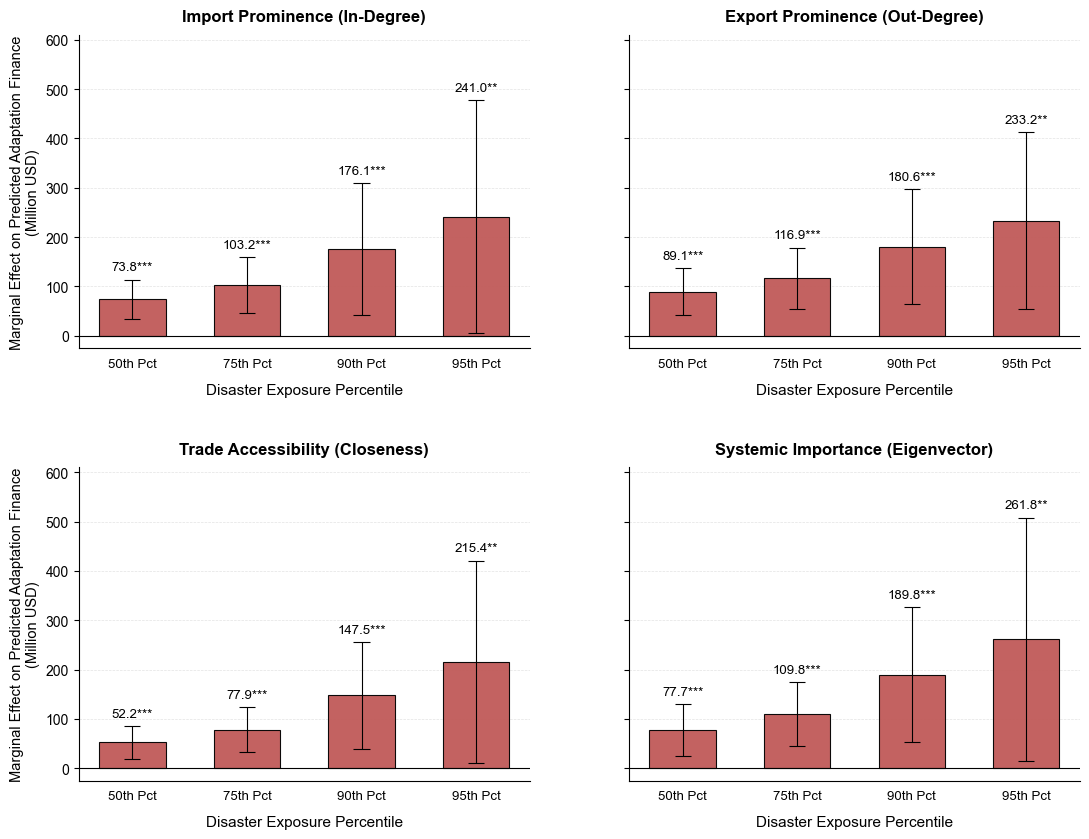

In [2]:
# Gravity IV
plot_moderation_effects(
    csv_file=f"{TABLES}/Moderation_disaster_Table2_Marginal_Effects_CF.csv",
    percentiles=['P50', 'P75', 'P90', 'P95'],
    moderator_label='Disaster Exposure Percentile',
    output_prefix='SuppFig_moderation_disaster_gravityIV_marginal_effects'
)


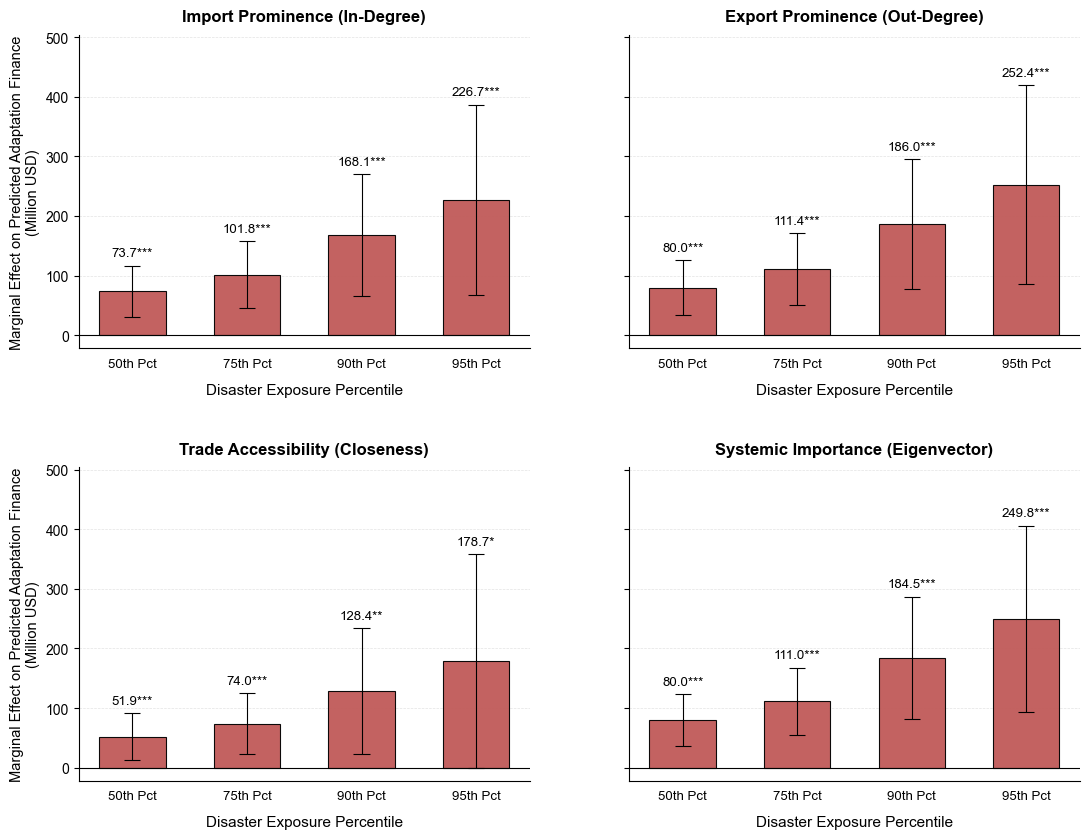

In [3]:
# Bartik IV
plot_moderation_effects(
    csv_file=f"{TABLES}/Moderation_disaster_Table2_Marginal_Effects_CF_Bartik.csv",
    percentiles=['P50', 'P75', 'P90', 'P95'],
    moderator_label='Disaster Exposure Percentile',
    output_prefix='SuppFig_moderation_disaster_BartikIV_marginal_effects'
)
